# Ejemplo de uso 1: Entrenamiento de un modelo y generación de imágenes

Este notebook ilustra como entrenar un modelo de difusión a partir de un dataset y una serie de parámetros, para posteriormente generar imágenes a partir de ruido.

En primer lugar, importamos todas las funciones que vamos a necesitar.

In [1]:
from diffusion_functions import train_model, generate_and_plot

El uso de este paquete Python para la generación de imágenes consta de dos pasos principales:
1. Entrenamiento del modelo. En este paso se especifica el número de épocas, así como el tipo de proceso de difusión y el scheduler a utilizar.
2. Generación de imágenes. En este segundo paso se requiere de nuevo tanto el tipo de proceso de difusión como el scheduler. También se debe especificar el sampler que se quiere utilizar para la generación de las imágenes, y la etiqueta de imagen que se quiere generar, siendo esto último un valor del 0 al 9, ya que tanto el dataset CIFAR-10 como MNIST utilizan esta nomenclatura para llamar a sus clases. También incluye un parámetro opcional, imputation, que por defecto está fijado en False. Si se marca en True, el modelo usará imputación durante la generación.

Las posibles opciones que están implementadas en este paquete y que, por tanto, se pueden utilizar, para cada parámetro son:
- n_epochs: un valor entero positivo. se recomienda que se encuentre entre 30 y 50.
- dataset: "mnist" o "cifar10". Por defecto, si no se especifica, así como si se introduce una cadena distinta, se usará CIFAR-10.
- diffusion_type: "ve" (Variance Exploding), "vp" (Variance Preserving), "subvp" (Sub-variance Preserving).
- schedule_type: "exponential", "linear", "cosine".
- sampler: "euler" (Euler-Maruyama), "pc" (Predictor corrector), "pf" (Probability Flow ODE), "expint" (Exponential Integrator).
- label: un valor entero entre 0 y 9
- imputation: True o False.

In [2]:
# Configuración del modelo y de la generación
n_epochs = 30
diffusion_type = "ve"
dataset = "cifar10"
schedule_type = "exponential"
sampler="euler"
label=2
imputation=True

### Paso 1: Entrenamiento del modelo

In [3]:
model = train_model(n_epochs=n_epochs, dataset=dataset, diffusion_type=diffusion_type, schedule_type = schedule_type)

Files already downloaded and verified


  3%|▎         | 1/30 [00:43<21:08, 43.73s/it]

Epoch 1/30 - Loss: 646.472689 - BPD: 0.000024


  7%|▋         | 2/30 [01:26<20:15, 43.42s/it]

Epoch 2/30 - Loss: 159.428669 - BPD: 0.000027


...

Epoch 28/30 - Loss: 102.551024 - BPD: 0.000008


 97%|█████████▋| 29/30 [18:16<00:42, 42.39s/it]

Epoch 29/30 - Loss: 102.753703 - BPD: 0.000009


100%|██████████| 30/30 [19:05<00:00, 38.20s/it]

Epoch 30/30 - Loss: 102.271471 - BPD: 0.000018


### Paso 2: Generación de imágenes

Files already downloaded and verified


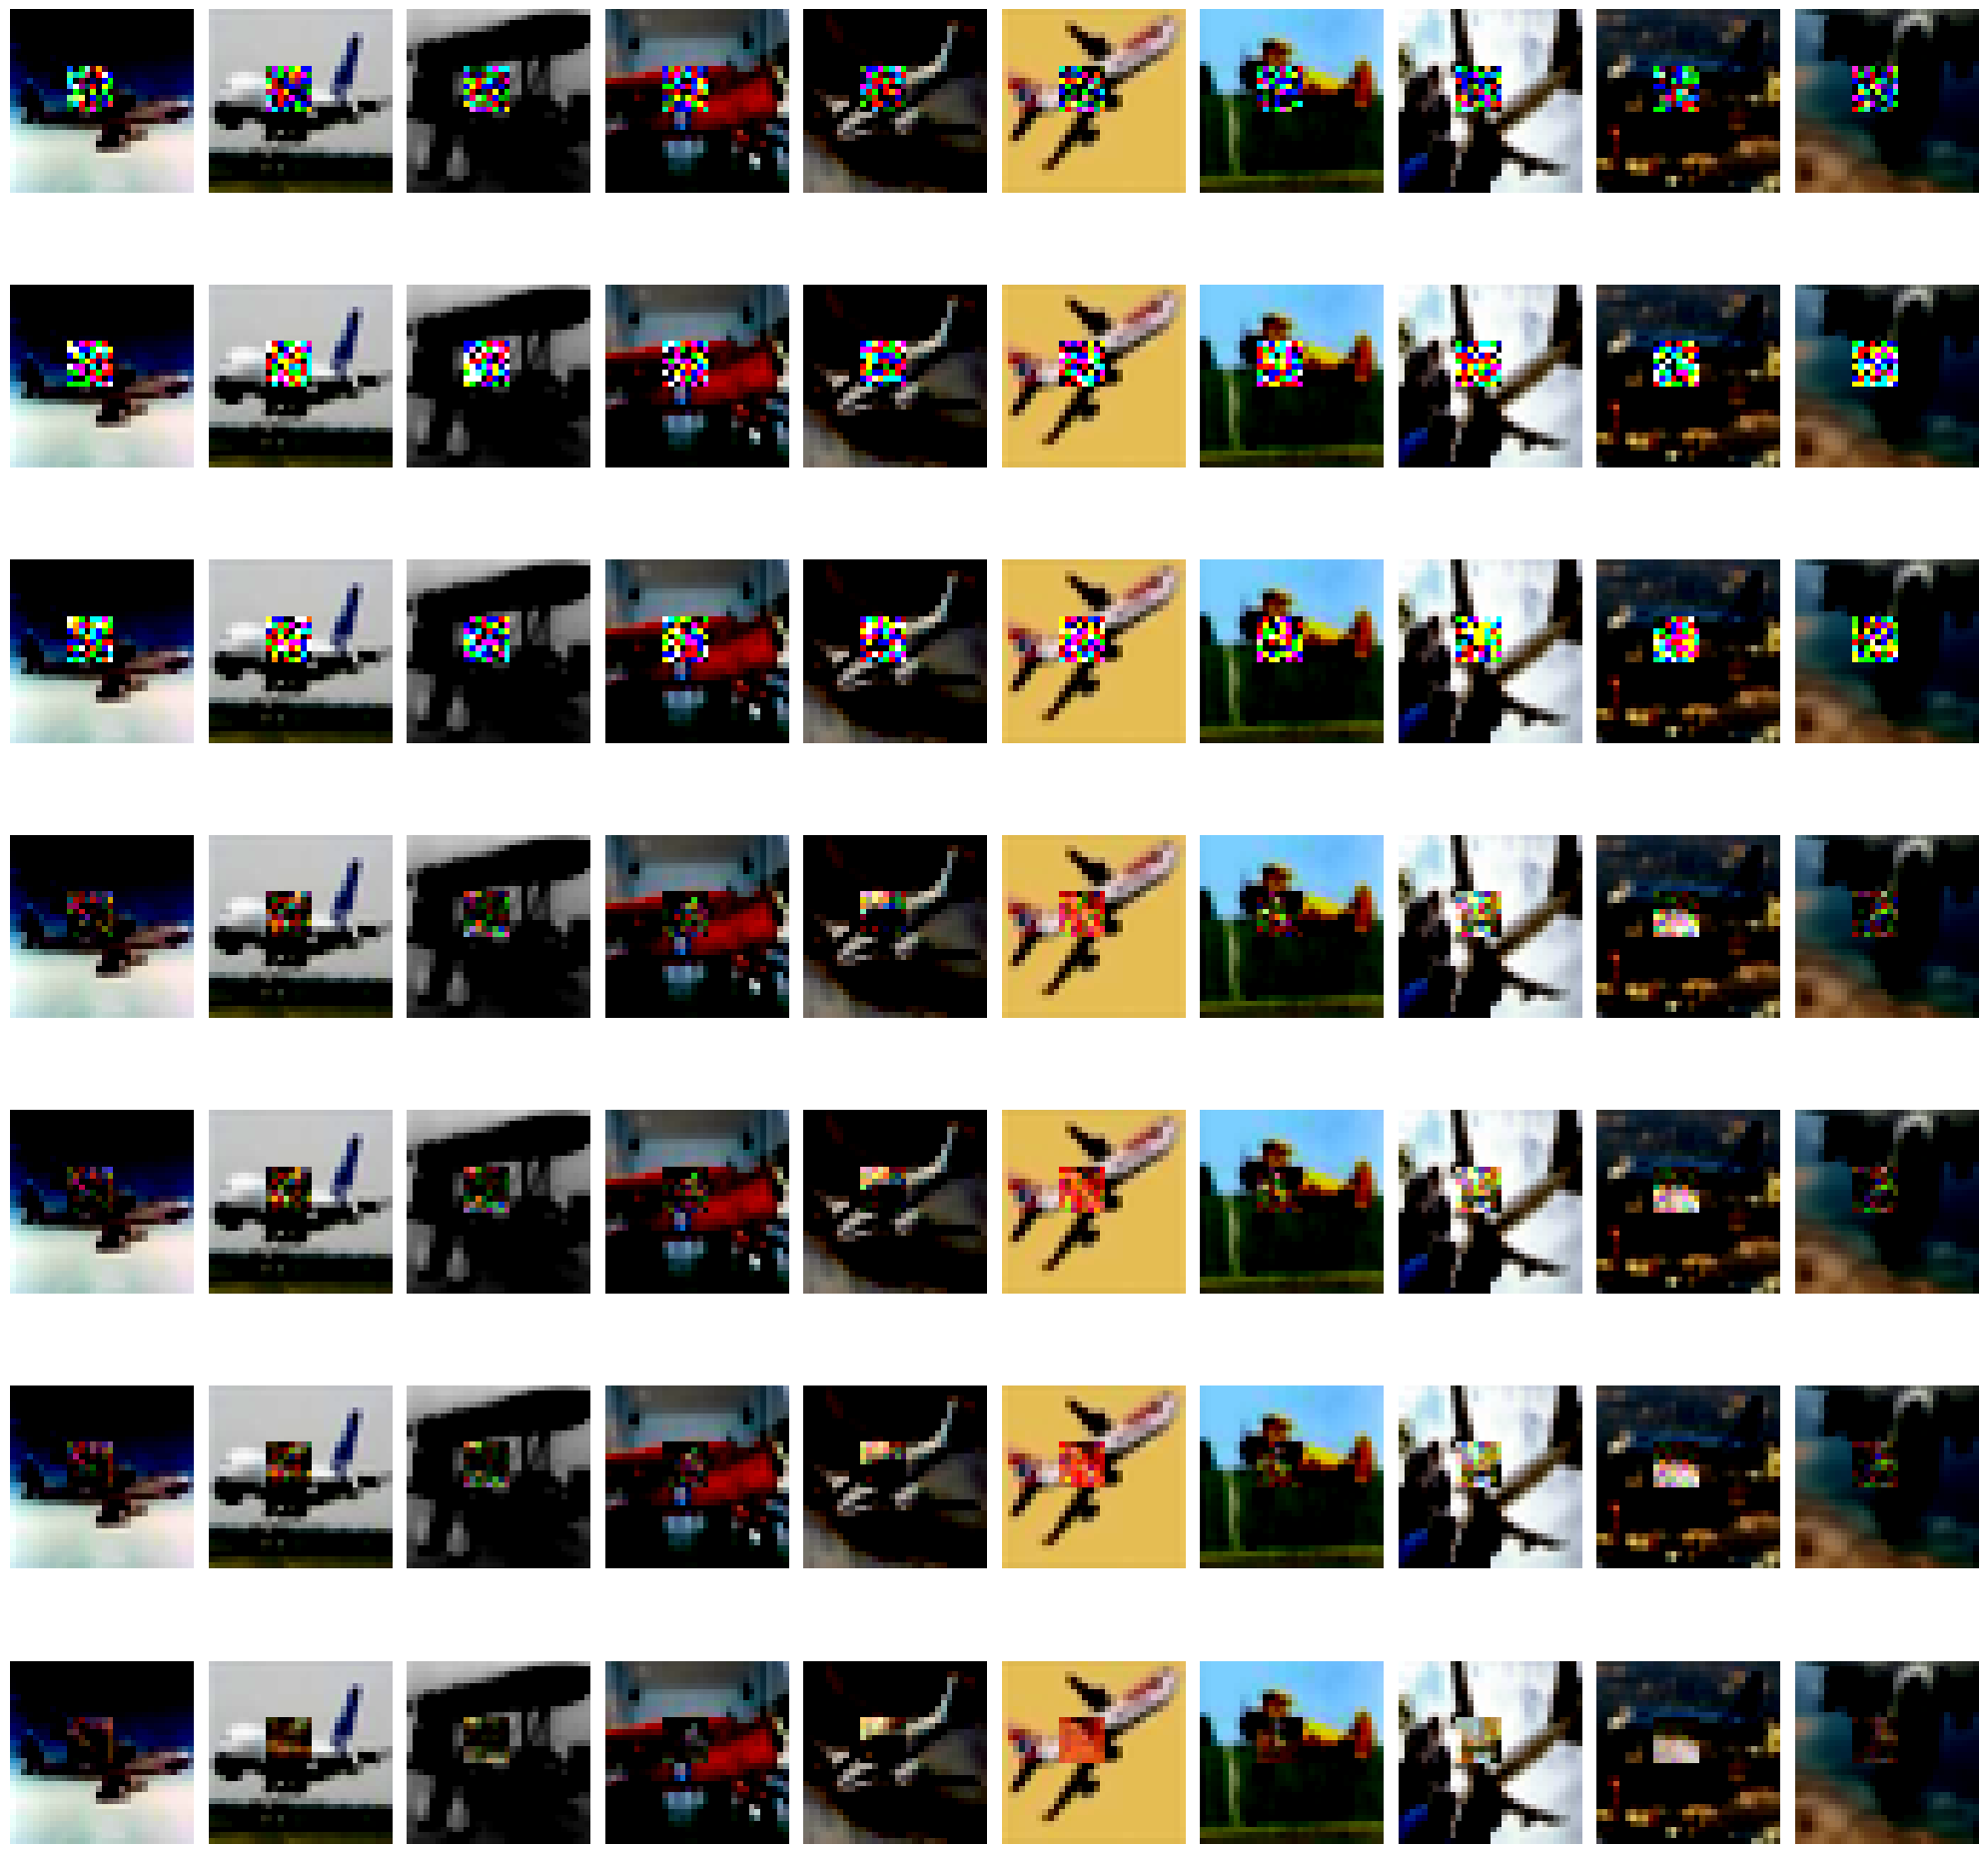

In [4]:
generate_and_plot(model, dataset=dataset, diffusion_type=diffusion_type, schedule_type=schedule_type, sampler="euler", label=0, imputation=True)